In [1]:
# 12. Prediction prerequisite and experiment configuration.
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
from pathlib import Path
import json, platform, time, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from attention_numpy import stable_softmax, scaled_dot_product_attention, self_attention
from preprocessing import load_imdb, clean_official_splits, tokenize
from experiment_utils import (seed_everything, build_vocabulary, collate_reviews,
    encode, SequenceClassifier, make_loader, train_run, load_run, evaluate,
    metric_record, predict_token_lists, retained_table, sha256)
BASE = Path.cwd()
OUT = BASE/'outputs'
OUT.mkdir(exist_ok=True)
confirmation_path = BASE/'prediction_confirmation.json'
assert confirmation_path.exists(), 'Complete W6 section 12 before executing notebook; see README.'
confirmation = json.loads(confirmation_path.read_text(encoding='utf-8'))
assert confirmation.get('completed_before_experiments') is True
assert confirmation.get('lab') == 'W6'
CONFIG = dict(seed=42, embedding_dim=64, hidden_size=64, batch_size=128,
              learning_rate=0.001, epochs=6, clip_grad_norm=1.0)
MAX_LENGTH = 100
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
seed_everything(CONFIG['seed'])
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 120)
print('W6 prediction confirmation:', confirmation)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else platform.processor())
print('Locked configuration:', CONFIG, 'max_length=', MAX_LENGTH)

def heatmap(A, tokens, title, path):
    A = np.asarray(A)
    fig, ax = plt.subplots(figsize=(max(6, len(tokens)*.55), max(5, len(tokens)*.5)))
    im = ax.imshow(A, cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(tokens)), tokens, rotation=60, ha='right')
    ax.set_yticks(range(len(tokens)), tokens)
    ax.set(xlabel='Key token (position)', ylabel='Query token (position)', title=title)
    if len(tokens) <= 12:
        for i in range(len(tokens)):
            for j in range(len(tokens)):
                ax.text(j,i,f'{A[i,j]:.2f}',ha='center',va='center',fontsize=7,
                        color='white' if A[i,j]<.45 else 'black')
    fig.colorbar(im, ax=ax, label='Attention weight')
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.show()

W6 prediction confirmation: {'lab': 'W6', 'completed_before_experiments': True, 'confirmed_by': 'user', 'confirmed_on_local_date': '2026-10-22', 'timezone': 'Asia/Saigon', 'statement': 'tôi đã tự viết 5 prediction W6 trước khi chạy code', 'note': "Records the user's confirmation only; does not contain or replace the original handwritten predictions."}
Device: cuda NVIDIA GeForce RTX 3050 Laptop GPU
Locked configuration: {'seed': 42, 'embedding_dim': 64, 'hidden_size': 64, 'batch_size': 128, 'learning_rate': 0.001, 'epochs': 6, 'clip_grad_norm': 1.0} max_length= 100


In [2]:
# 13. Scaled dot-product attention: QK^T -> divide sqrt(d_key) -> softmax -> multiply V.
# Independent synthetic demonstration; not the handwritten inputs of sections 14 or 21.
rng13 = np.random.default_rng(13)
Q13 = rng13.normal(size=(2, 4))
K13 = rng13.normal(size=(3, 4))
V13 = rng13.normal(size=(3, 2))
d_key13 = K13.shape[1]
dot_product_scores13 = Q13 @ K13.T
scaled_scores13 = dot_product_scores13 / np.sqrt(d_key13)
attention_weights13 = stable_softmax(scaled_scores13, axis=-1)
context13 = attention_weights13 @ V13
print('Q:'); display(pd.DataFrame(Q13))
print('K:'); display(pd.DataFrame(K13))
print('V:'); display(pd.DataFrame(V13))
print('QK^T:'); display(pd.DataFrame(dot_product_scores13))
print('d_key =', d_key13, '; sqrt(d_key) =', np.sqrt(d_key13))
print('scaled_scores = QK^T / sqrt(d_key):'); display(pd.DataFrame(scaled_scores13))
print('attention_weights = softmax(scaled_scores), row-wise:'); display(pd.DataFrame(attention_weights13))
print('context = attention_weights @ V:'); display(pd.DataFrame(context13))
assert np.allclose(attention_weights13.sum(axis=-1), 1)
np.savez(OUT/'section13_scaling_demo.npz', Q=Q13, K=K13, V=V13,
         dot_product_scores=dot_product_scores13, scores=scaled_scores13,
         attention_weights=attention_weights13, context=context13)

# Supplemental dimension experiment, keeping the same raw scores within each scaled/unscaled pair.
rng_scale = np.random.default_rng(42)
scale_rows = []
for d in [4, 16, 64, 256]:
    Q_scale = rng_scale.normal(size=(256, d))
    K_scale = rng_scale.normal(size=(32, d))
    raw_scores = Q_scale @ K_scale.T
    for scaling in [False, True]:
        S_scale = raw_scores / np.sqrt(d) if scaling else raw_scores
        A_scale = stable_softmax(S_scale)
        scale_rows.append(dict(d_key=d, scaled=scaling, score_std=S_scale.std(),
            mean_max_weight=A_scale.max(axis=1).mean(),
            mean_entropy_nats=(-A_scale*np.log(np.clip(A_scale, 1e-300, 1))).sum(axis=1).mean()))
scale_table = pd.DataFrame(scale_rows)
scale_table.to_csv(OUT/'scaling.csv', index=False)
print('Supplemental scaling-by-dimension measurements:'); display(scale_table)

Q:


,0,1,2,3
0,1.826757,-3.078332,0.958064,0.069637
1,1.318250,0.385629,1.827259,0.031744


K:


,0,1,2,3
0,-0.516229,0.580485,0.432107,-0.356839
1,-0.247304,0.719441,0.704316,-0.493934
2,-0.367714,-1.806790,1.679207,-0.224291


V:


...

,0,1,2
0,0.011819,0.013833,0.974348
1,0.210585,0.330452,0.458963


context = attention_weights @ V:


,0,1
0,0.352830,1.468976
1,1.070084,1.275469


Supplemental scaling-by-dimension measurements:


,d_key,scaled,score_std,mean_max_weight,mean_entropy_nats
0,4,False,1.870566,0.343689,2.310470
1,4,True,0.935283,0.158798,3.062143
2,16,False,4.132629,0.629083,1.120104
3,16,True,1.033157,0.173725,2.983159
4,64,False,7.842924,0.812267,0.509592
5,64,True,0.980366,0.154887,3.041291
6,256,False,16.297079,0.899266,0.262534
7,256,True,1.018567,0.167475,3.002884


Fixed score vector s = [ 0.3 -0.8  1.7  0.4]
Entropy uses natural logarithms (nats).


,Temperature,Max weight,Entropy,Nhận xét
0,0.5,0.875794,0.480376,"Tập trung hơn T=1: max weight cao hơn, entropy thấp hơn. So với T=1: max weight +0.251267; entropy -0.555420 nats."
1,1.0,0.624526,1.035796,Mốc T=1 để đối chiếu. So với T=1: max weight +0.000000; entropy +0.000000 nats.
2,2.0,0.433814,1.288506,"Phẳng hơn T=1: max weight thấp hơn, entropy cao hơn. So với T=1: max weight -0.190712; entropy +0.252710 nats."


,temperature,weight_0,weight_1,weight_2,weight_3
0,0.5,0.053257,0.005901,0.875794,0.065048
1,1.0,0.154006,0.051264,0.624526,0.170203
2,2.0,0.215426,0.124290,0.433814,0.226471


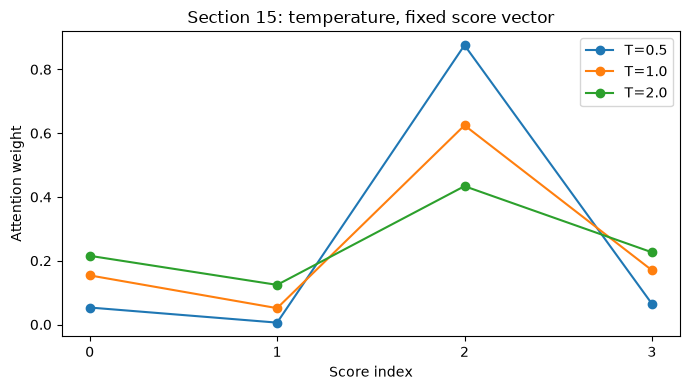

Nhận xét tự động từ số liệu trên cùng score vector:
T tăng 0.5 -> 1.0 -> 2.0; max weight giảm: True ; entropy tăng: True
Max weight: [0.875794, 0.624526, 0.433814] ; entropy (nats): [0.480376, 1.035796, 1.288506]


In [3]:
# 15. Temperature: same score vector, T = 0.5 / 1.0 / 2.0, max weight and entropy.
score_vector = np.array([0.3, -0.8, 1.7, 0.4])
print('Fixed score vector s =', score_vector)
print('Entropy uses natural logarithms (nats).')
temperature_rows = []
temperature_weights_rows = []
for temperature in [0.5, 1.0, 2.0]:
    temperature_weights = stable_softmax(score_vector / temperature)
    temperature_rows.append(dict(temperature=temperature,
        max_weight=float(temperature_weights.max()),
        entropy_nats=float(-np.sum(temperature_weights*np.log(temperature_weights))),
        nhan_xet=(f"So với T=1: max weight {float(temperature_weights.max()-stable_softmax(score_vector).max()):+.6f}; "
                  f"entropy {float(-np.sum(temperature_weights*np.log(temperature_weights)) + np.sum(stable_softmax(score_vector)*np.log(stable_softmax(score_vector)))):+.6f} nats.")))
    temperature_weights_rows.append(dict(temperature=temperature,
        **{f'weight_{i}': float(w) for i, w in enumerate(temperature_weights)}))
temperature_table = pd.DataFrame(temperature_rows)
temperature_weights_table = pd.DataFrame(temperature_weights_rows)

reference_row = temperature_table.loc[temperature_table.temperature.eq(1.0)].iloc[0]
for i,row in temperature_table.iterrows():
    if row.max_weight > reference_row.max_weight and row.entropy_nats < reference_row.entropy_nats:
        observed = 'Tập trung hơn T=1: max weight cao hơn, entropy thấp hơn.'
    elif row.max_weight < reference_row.max_weight and row.entropy_nats > reference_row.entropy_nats:
        observed = 'Phẳng hơn T=1: max weight thấp hơn, entropy cao hơn.'
    else:
        observed = 'Mốc T=1 để đối chiếu.'
    temperature_table.at[i,'nhan_xet'] = observed+' '+row.nhan_xet

temperature_table.to_csv(OUT/'temperature.csv', index=False)
temperature_weights_table.to_csv(OUT/'temperature_weights.csv', index=False)
with pd.option_context('display.max_colwidth',None):
    display(temperature_table.rename(columns={'temperature':'Temperature',
        'max_weight':'Max weight', 'entropy_nats':'Entropy', 'nhan_xet':'Nhận xét'}))
display(temperature_weights_table)
fig, ax = plt.subplots(figsize=(7, 4))
for row in temperature_weights_rows:
    weights_for_plot = [row[f'weight_{i}'] for i in range(len(score_vector))]
    ax.plot(range(len(score_vector)), weights_for_plot, marker='o', label=f"T={row['temperature']}")
ax.set_xticks(range(len(score_vector)))
ax.set(xlabel='Score index', ylabel='Attention weight', title='Section 15: temperature, fixed score vector')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'temperature.png', dpi=160); plt.show()
temperature_ordered=temperature_table.sort_values('temperature')
max_decreases=bool(np.all(np.diff(temperature_ordered.max_weight)<0))
entropy_increases=bool(np.all(np.diff(temperature_ordered.entropy_nats)>0))
print('Nhận xét tự động từ số liệu trên cùng score vector:')
print('T tăng 0.5 -> 1.0 -> 2.0; max weight giảm:', max_decreases,
      '; entropy tăng:', entropy_increases)
print('Max weight:', temperature_ordered.max_weight.round(6).tolist(),
      '; entropy (nats):', temperature_ordered.entropy_nats.round(6).tolist())


In [4]:
# 16. Core implementation: show all three returned arrays, not only their shapes.
# The implementation is in attention_numpy.py; no built-in attention layer is used.
rng16 = np.random.default_rng(61)
Q = rng16.normal(size=(2, 5))
K = rng16.normal(size=(4, 5))
V = rng16.normal(size=(4, 3))
scores, attention_weights, context = scaled_dot_product_attention(Q, K, V)
print('Q:'); display(pd.DataFrame(Q))
print('K:'); display(pd.DataFrame(K))
print('V:'); display(pd.DataFrame(V))
print('scores = Q @ K.T / sqrt(d_key):'); display(pd.DataFrame(scores))
print('attention_weights = softmax(scores), row-wise:'); display(pd.DataFrame(attention_weights))
print('context = attention_weights @ V:'); display(pd.DataFrame(context))

assert scores.shape == (2, 4) and attention_weights.shape == (2, 4) and context.shape == (2, 3)
assert np.allclose(scores, Q @ K.T / np.sqrt(K.shape[1]))
assert np.allclose(attention_weights.sum(axis=1), 1) and np.all(attention_weights >= 0)
reference = torch.softmax(torch.tensor(scores), dim=-1).numpy()
assert np.allclose(attention_weights, reference)
assert np.allclose(context, reference @ V)
np.savez(OUT/'core_attention_outputs.npz', Q=Q, K=K, V=V, scores=scores,
         attention_weights=attention_weights, context=context)
for name, array in [('scores', scores), ('attention_weights', attention_weights), ('context', context)]:
    pd.DataFrame(array).to_csv(OUT/f'core_{name}.csv', index=False)
core_verification = dict(scores_shape=list(scores.shape), attention_weights_shape=list(attention_weights.shape),
    context_shape=list(context.shape), row_sums=attention_weights.sum(axis=1).tolist(),
    maximum_weight_reference_difference=float(np.max(np.abs(attention_weights-reference))),
    all_three_returned_arrays_displayed=True)
(OUT/'core_implementation_verification.json').write_text(json.dumps(core_verification, indent=2), encoding='utf-8')
print('Implementation checks:'); display(pd.DataFrame([core_verification]))

Q:


,0,1,2,3,4
0,-0.566764,-1.056574,1.06208,-1.129352,-1.779405
1,0.654956,0.841251,-0.94911,-0.565330,2.779727


K:


,0,1,2,3,4
0,-1.017438,-0.505789,1.178756,0.745406,1.611804
1,0.817756,-0.407679,0.118440,-0.550128,0.805757
2,0.508356,-1.230798,0.484528,-0.819338,0.072190
3,-0.381020,0.283052,-2.595607,0.444396,-1.423226


V:


...

,0,1,2,3
0,0.114167,0.151151,0.589482,0.145200
1,0.336839,0.478009,0.117930,0.067222


context = attention_weights @ V:


,0,1,2
0,0.136981,-0.101306,0.090959
1,0.073476,-0.274285,0.301703


Implementation checks:


,scores_shape,attention_weights_shape,context_shape,row_sums,maximum_weight_reference_difference,all_three_returned_arrays_displayed
0,"[2, 4]","[2, 4]","[2, 3]","[0.9999999999999998, 1.0000000000000002]",1.387779e-17,True


In [5]:
# 17. Required numerical-stability runtime test; explanation belongs in the handwritten scan.
x=np.array([1000.,1001.,1002.])
stable=stable_softmax(x)
with np.errstate(over='ignore',invalid='ignore'):
    naive=np.exp(x)/np.exp(x).sum()
stability=pd.DataFrame({'input':x,'stable_weight':stable,'naive_weight':naive})
assert np.isfinite(stable).all() and np.isclose(stable.sum(),1)
assert np.allclose(stable,stable_softmax(x-987.))
stability.to_csv(OUT/'numerical_stability.csv',index=False)
display(stability)
print('Kiểm tra tự động: stable weights hữu hạn =', bool(np.isfinite(stable).all()),
      '; tổng weights =', float(stable.sum()), '; naive có giá trị không hữu hạn =', bool((~np.isfinite(naive)).any()))


,input,stable_weight,naive_weight
0,1000.0,0.090031,NaN
1,1001.0,0.244728,NaN
2,1002.0,0.665241,NaN


Kiểm tra tự động: stable weights hữu hạn = True ; tổng weights = 0.9999999999999999 ; naive có giá trị không hữu hạn = True


,Token,Raw dot-product score,Score,Attention
0,The,2.984884,1.055316,0.257532
1,movie,-2.541421,-0.898528,0.036500
2,was,0.794766,0.280992,0.118726
3,surprisingly,-0.926806,-0.327675,0.064596
4,good,-2.704769,-0.956280,0.034451
5,despite,0.191758,0.067797,0.095930
6,a,-0.072741,-0.025718,0.087366
7,very,1.764818,0.623958,0.167299
8,slow,-0.581553,-0.205610,0.072982
9,beginning,-0.925873,-0.327346,0.064617


SIMULATED, UNTRAINED; query A is not a learned sentiment query. Context shape: (1, 6)


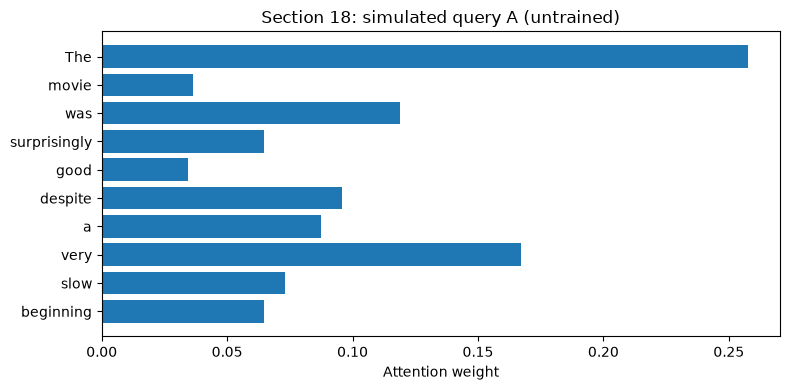

Thống kê tự động: token có weight lớn nhất = 'The', position=0, weight=0.257532; tổng weights=1.000000.


In [6]:
# 18. Simulated query and seeded untrained key/value vectors.
demo_tokens='The movie was surprisingly good despite a very slow beginning'.split()
rng=np.random.default_rng(18)
demo_K=rng.normal(size=(len(demo_tokens),8));demo_V=rng.normal(size=(len(demo_tokens),6))
query_A=rng.normal(size=(1,8));query_B=rng.normal(size=(1,8))
S,A,C=scaled_dot_product_attention(query_A,demo_K,demo_V)
demo_table=pd.DataFrame({'token':demo_tokens,'dot_product_score':(query_A@demo_K.T)[0],
                         'scaled_score':S[0],'attention':A[0]})
demo_table.to_csv(OUT/'simulated_query_A.csv',index=False)
display(demo_table.rename(columns={'token':'Token','dot_product_score':'Raw dot-product score',
    'scaled_score':'Score','attention':'Attention'}))
print('SIMULATED, UNTRAINED; query A is not a learned sentiment query. Context shape:',C.shape)
fig,ax=plt.subplots(figsize=(8,4));ax.barh(demo_tokens[::-1],A[0][::-1])
ax.set(xlabel='Attention weight',title='Section 18: simulated query A (untrained)')
fig.tight_layout();fig.savefig(OUT/'simulated_distribution.png',dpi=160);plt.show()
peak18=int(np.argmax(A[0]))
print(f"Thống kê tự động: token có weight lớn nhất = {demo_tokens[peak18]!r}, "
      f"position={peak18}, weight={A[0,peak18]:.6f}; tổng weights={A[0].sum():.6f}.")


,token,query_A_weight,query_B_weight
0,The,0.257532,0.211946
1,movie,0.036500,0.005600
2,was,0.118726,0.016654
3,surprisingly,0.064596,0.016558
4,good,0.034451,0.032584
5,despite,0.095930,0.044559
6,a,0.087366,0.090692
7,very,0.167299,0.543579
8,slow,0.072982,0.013802
9,beginning,0.064617,0.024025


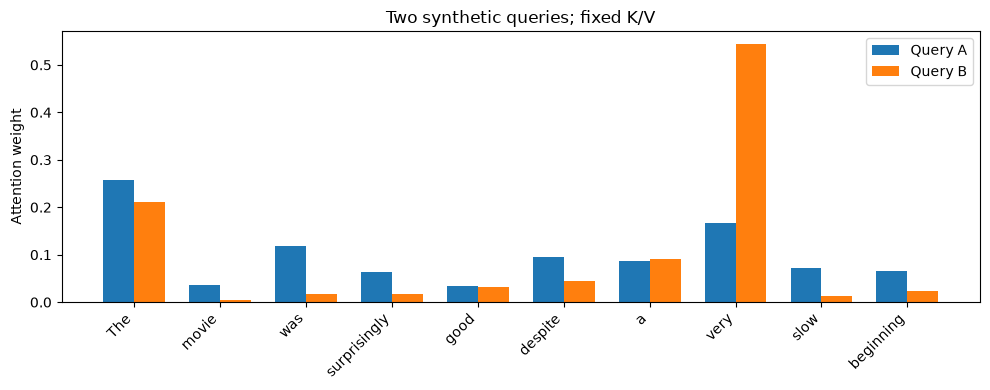

Đối chiếu số liệu khi chỉ thay query:


,same_tokens,same_keys,same_values,weights_changed,l1_weight_difference,query_A_top_token,query_B_top_token
0,True,True,True,True,0.759212,The,very


In [7]:
# 19. Change only the query; keep tokens, keys and values fixed.
SB,AB,CB=scaled_dot_product_attention(query_B,demo_K,demo_V)
query_table=demo_table[['token']].copy()
query_table['query_A_weight']=A[0];query_table['query_B_weight']=AB[0]
query_table.to_csv(OUT/'query_comparison.csv',index=False);display(query_table)
np.savez(OUT/'simulated_qkv.npz',K=demo_K,V=demo_V,query_A=query_A,query_B=query_B)
fig,ax=plt.subplots(figsize=(10,4));x=np.arange(len(demo_tokens))
ax.bar(x-.18,A[0],width=.36,label='Query A');ax.bar(x+.18,AB[0],width=.36,label='Query B')
ax.set_xticks(x,demo_tokens,rotation=45,ha='right');ax.set(ylabel='Attention weight',title='Two synthetic queries; fixed K/V')
ax.legend();fig.tight_layout();fig.savefig(OUT/'query_comparison.png',dpi=160);plt.show()
query_measurements=pd.DataFrame([dict(same_tokens=True,same_keys=True,same_values=True,
    weights_changed=not np.allclose(A,AB),l1_weight_difference=float(np.abs(A-AB).sum()),
    query_A_top_token=demo_tokens[int(A.argmax())],query_B_top_token=demo_tokens[int(AB.argmax())])])
query_measurements.to_csv(OUT/'query_change_measurements.csv',index=False)
print('Đối chiếu số liệu khi chỉ thay query:');display(query_measurements)


In [8]:
# 20. NumPy self-attention: Q, K, V from the same X; independent demonstration, not exercise 21.
tokens22=['this','film','surprised','me']
rng=np.random.default_rng(22)
X=rng.normal(size=(4,6));WQ=rng.normal(size=(6,4));WK=rng.normal(size=(6,4));WV=rng.normal(size=(6,5))
q,k,v,s,a,c=self_attention(X,WQ,WK,WV)
assert a.shape==(4,4) and c.shape==(4,5) and np.allclose(a.sum(axis=1),1)
np.savez(OUT/'numpy_self_attention_demo.npz',X=X,WQ=WQ,WK=WK,WV=WV,Q=q,K=k,V=v,scores=s,attention=a,context=c)

for label,array in [('X',X),('WQ',WQ),('WK',WK),('WV',WV),('Q = X @ WQ',q),
    ('K = X @ WK',k),('V = X @ WV',v),('QK^T',q@k.T),
    ('scaled_scores',s),('attention_weights',a),('context = attention_weights @ V',c)]:
    print(label+':');display(pd.DataFrame(array))


X:


,0,1,2,3,4,5
0,-1.397618,-1.204009,-1.302269,-0.622685,1.447280,-1.601314
1,0.943969,1.262472,-0.355461,-0.700936,0.472115,1.214558
2,2.155531,0.891811,1.593843,-0.450292,-0.874217,-1.719773
3,-1.153703,-0.363434,0.192995,-1.313101,0.816086,-0.103049


WQ:


,0,1,2,3
0,-0.642201,-0.765289,2.020688,0.169228
1,-0.897927,-0.953982,1.837824,-0.578351
2,1.188704,1.423274,-2.324401,1.350975
3,-0.208432,-1.084129,-0.543842,0.560896
4,0.373977,0.425514,-0.724896,1.279084
5,1.502130,1.834064,1.000463,1.894315


WK:


...

,0,1,2,3
0,10.015782,-5.354346,0.698171,5.903820
1,-0.912501,0.201996,-7.565411,-5.645732
2,20.035721,-14.900003,-8.758002,4.569386
3,-11.249497,11.398534,5.127102,-1.314181


attention_weights:


,0,1,2,3
0,9.838011e-01,2.078480e-07,8.837314e-05,1.611035e-02
1,2.464194e-01,7.510947e-01,3.179456e-04,2.167997e-03
2,9.999998e-01,6.723690e-16,3.126403e-13,1.918915e-07
3,1.456344e-10,9.981110e-01,1.885951e-03,3.006884e-06


context = attention_weights @ V:


,0,1,2,3,4
0,-2.610040,3.282798,-2.928877,1.655207,-0.120337
1,1.124375,2.157729,-0.810145,1.254392,-0.258099
2,-2.622499,3.337141,-2.954803,1.661948,-0.064248
3,2.355996,1.767963,-0.098005,1.117228,-0.312983


,0:this,1:film,2:surprised,3:me
0:this,9.838011e-01,2.078480e-07,8.837314e-05,1.611035e-02
1:film,2.464194e-01,7.510947e-01,3.179456e-04,2.167997e-03
2:surprised,9.999998e-01,6.723690e-16,3.126403e-13,1.918915e-07
3:me,1.456344e-10,9.981110e-01,1.885951e-03,3.006884e-06


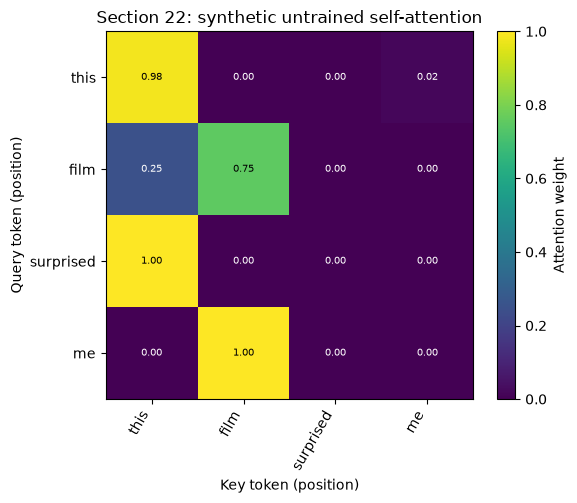

A shape: (4, 4) ; row sums: [1. 1. 1. 1.]


In [9]:
# 22. Attention matrix: full row-normalized matrix and heatmap from section 20.
matrix22=pd.DataFrame(a,index=[f'{i}:{t}' for i,t in enumerate(tokens22)],
    columns=[f'{i}:{t}' for i,t in enumerate(tokens22)])
matrix22.to_csv(OUT/'numpy_attention_matrix.csv')
display(matrix22)
heatmap(a,tokens22,'Section 22: synthetic untrained self-attention',OUT/'numpy_self_attention_heatmap.png')
print('A shape:',a.shape,'; row sums:',a.sum(axis=1))


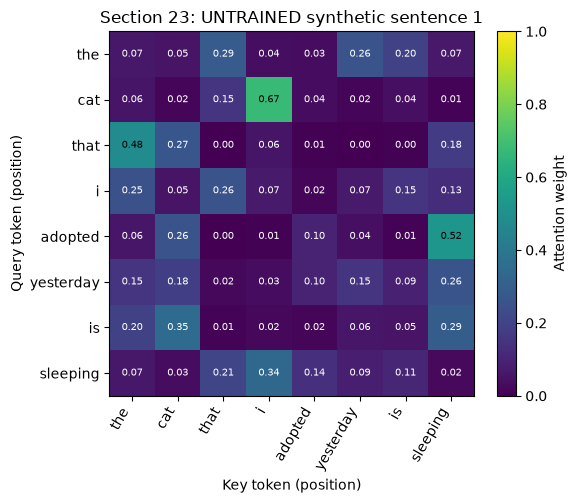

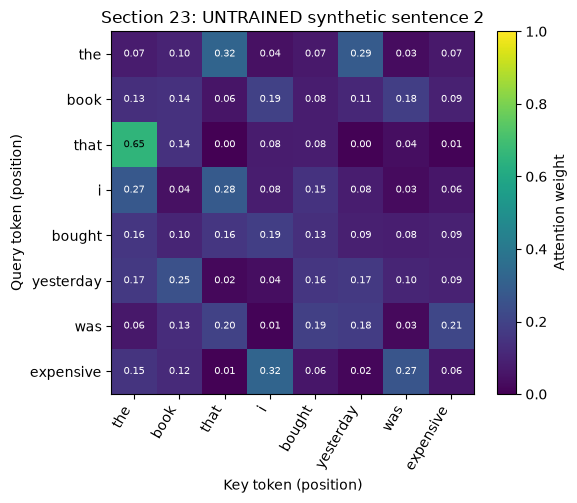

,sentence,query_token,query_position,key_token,key_position,attention,weights_source
0,The cat that I adopted yesterday is sleeping.,cat,1,the,0,0.057668,seeded_untrained
1,The cat that I adopted yesterday is sleeping.,cat,1,cat,1,0.015633,seeded_untrained
2,The cat that I adopted yesterday is sleeping.,cat,1,that,2,0.152140,seeded_untrained
3,The cat that I adopted yesterday is sleeping.,cat,1,i,3,0.673658,seeded_untrained
4,The cat that I adopted yesterday is sleeping.,cat,1,adopted,4,0.035001,seeded_untrained
5,The cat that I adopted yesterday is sleeping.,cat,1,yesterday,5,0.015055,seeded_untrained
6,The cat that I adopted yesterday is sleeping.,cat,1,is,6,0.039272,seeded_untrained
7,The cat that I adopted yesterday is sleeping.,cat,1,sleeping,7,0.011573,seeded_untrained
8,The cat that I adopted yesterday is sleeping.,adopted,4,the,0,0.062114,seeded_untrained
9,The cat that I adopted yesterday is sleeping.,adopted,4,cat,1,0.255287,seeded_untrained


Top 3 keys theo weight cho từng query token (untrained; số liệu, chưa diễn giải ngôn ngữ):


,query_token,query_position,key_token,key_position,attention,weights_source
27,book,1,i,3,0.194381,seeded_untrained
30,book,1,was,6,0.184104,seeded_untrained
25,book,1,book,1,0.143784,seeded_untrained
35,bought,4,i,3,0.186837,seeded_untrained
34,bought,4,that,2,0.157973,seeded_untrained
32,bought,4,the,0,0.157584,seeded_untrained
43,expensive,7,i,3,0.321546,seeded_untrained
46,expensive,7,was,6,0.265409,seeded_untrained
40,expensive,7,the,0,0.149855,seeded_untrained
15,adopted,4,sleeping,7,0.524367,seeded_untrained


In [10]:
# 23. Required sentences; random, untrained projections are explicitly labeled.
sentences23=['The cat that I adopted yesterday is sleeping.',
             'The book that I bought yesterday was expensive.']
rng=np.random.default_rng(23)
all_tokens=sorted(set(t for text in sentences23 for t in tokenize(text)))
toy_vocab={t:rng.normal(size=8) for t in all_tokens}
projections=[rng.normal(size=(8,8))/np.sqrt(8) for _ in range(3)]
probe_rows=[]
for sentence_index,text in enumerate(sentences23):
    tokens=tokenize(text);X=np.array([toy_vocab[t] for t in tokens])
    q,k,v,s,a,c=self_attention(X,*projections)
    heatmap(a,tokens,f'Section 23: UNTRAINED synthetic sentence {sentence_index+1}',
            OUT/f'section23_untrained_{sentence_index+1}.png')
    pd.DataFrame(a,index=[f'{i}:{t}' for i,t in enumerate(tokens)],
                 columns=[f'{i}:{t}' for i,t in enumerate(tokens)]).to_csv(OUT/f'section23_matrix_{sentence_index+1}.csv')
    probes=['cat','adopted','sleeping'] if sentence_index==0 else ['book','bought','expensive']
    for token in probes:
        i=tokens.index(token)
        for j,target in enumerate(tokens):
            probe_rows.append(dict(sentence=text,query_token=token,query_position=i,
                key_token=target,key_position=j,attention=a[i,j],weights_source='seeded_untrained'))
probe_table=pd.DataFrame(probe_rows);probe_table.to_csv(OUT/'section23_token_rows.csv',index=False)
display(probe_table)
top23=(probe_table.sort_values(['sentence','query_token','attention'],ascending=[True,True,False])
    .groupby(['sentence','query_token'],sort=False).head(3))
top23.to_csv(OUT/'section23_top_keys.csv',index=False)
print('Top 3 keys theo weight cho từng query token (untrained; số liệu, chưa diễn giải ngôn ngữ):')
display(top23[['query_token','query_position','key_token','key_position','attention','weights_source']])


In [11]:
# 24a. Same IMDb task, cleaning and split manifest as LAB05; train-only vocabulary.
raw=load_imdb(BASE/'data')
cleaned,cleaning_audit=clean_official_splits(raw)
manifest=pd.read_csv(BASE/'data/lab04_split_manifest.csv')
joined=manifest.merge(cleaned,on='sample_id',suffixes=('_manifest',''),validate='one_to_one')
assert len(joined)==len(cleaned)==len(manifest)
assert joined.label_manifest.eq(joined.label).all()
assert joined.document_key_manifest.eq(joined.document_key).all()
frames={name:joined.loc[joined.split.eq(name)].reset_index(drop=True) for name in ['train','validation','test']}
train,validation,test=[frames[name] for name in ['train','validation','test']]
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not(set(frames[a].document_key)&set(frames[b].document_key))
vocab=build_vocabulary(train.tokens,max_size=20000,min_count=2)
(OUT/'vocabulary.json').write_text(json.dumps(vocab,ensure_ascii=False),encoding='utf-8')
split_table=joined.groupby(['split','label']).size().rename('samples').reset_index()
split_table.to_csv(OUT/'split_distribution.csv',index=False)
cleaning_audit.to_csv(OUT/'cleaning_audit.csv',index=False)
retention=retained_table(frames,lengths=(MAX_LENGTH,))
retention.to_csv(OUT/'retention.csv',index=False)
display(split_table,cleaning_audit,retention)
print('Vocabulary:',len(vocab),'PAD=0 UNK=1; right truncation, right padding')

,split,label,samples
0,test,0,12264
1,test,1,12411
2,train,0,9944
3,train,1,9976
4,validation,0,2487
5,validation,1,2494


,official_split,original,invalid_or_empty_removed,conflicting_label_groups,conflicting_label_rows_removed,duplicate_extra_rows_removed,cross_split_rows_removed,retained
0,train,25000,0,0,0,99,0,24901
1,test,25000,0,0,0,202,123,24675


,split,max_length,documents,total_tokens,retained_tokens,percent_tokens_retained,percent_documents_truncated,percent_documents_padded,percent_padding_at_fixed_length
0,train,100,19920,4661801,1917796,41.138521,87.911647,11.887550,3.725100
1,validation,100,4981,1168983,480203,41.078698,88.114836,11.704477,3.593054
2,test,100,24675,5645119,2370228,41.987211,87.371834,12.385005,3.942128


Vocabulary: 20000 PAD=0 UNK=1; right truncation, right padding


lstm_100: epoch 1/6 train=0.6772 val=0.6064 val_f1=0.7566 train_s=6.5


lstm_100: epoch 2/6 train=0.4735 val=0.4297 val_f1=0.8057 train_s=4.2


lstm_100: epoch 3/6 train=0.3054 val=0.4178 val_f1=0.8241 train_s=3.4


lstm_100: epoch 4/6 train=0.2101 val=0.4585 val_f1=0.8186 train_s=3.7


lstm_100: epoch 5/6 train=0.1441 val=0.5577 val_f1=0.7993 train_s=3.2


...

attention_100: epoch 3/6 train=0.2267 val=0.3885 val_f1=0.8325 train_s=1.4


attention_100: epoch 4/6 train=0.1556 val=0.4644 val_f1=0.8299 train_s=1.1


attention_100: epoch 5/6 train=0.0989 val=0.6155 val_f1=0.8161 train_s=1.2


attention_100: epoch 6/6 train=0.0562 val=0.8004 val_f1=0.8052 train_s=1.2


,architecture,parameters,training_time_seconds,selected_epoch,validation_accuracy,validation_f1,validation_loss
0,LSTM,1313345,23.294587,3,0.824332,0.824121,0.417831
1,Attention,1292353,8.215281,2,0.844007,0.842489,0.361968


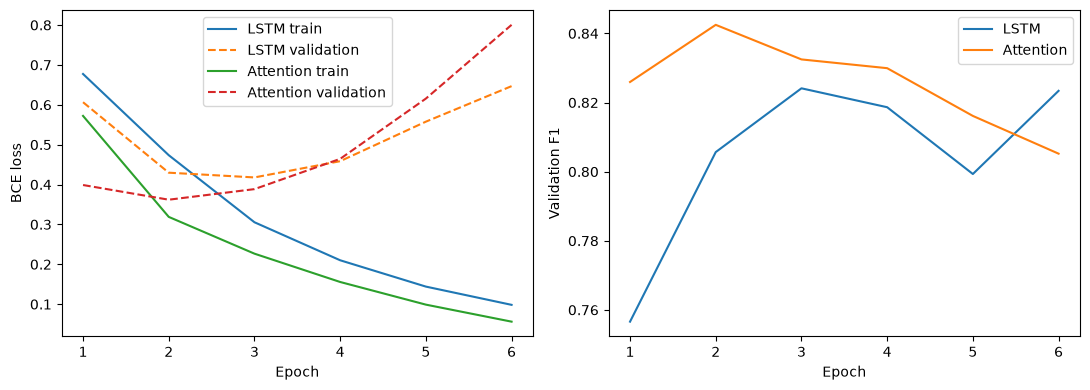

In [12]:
# 24b. Both models train from scratch with the same data, embeddings, seed and budget.
runs={};histories=[]
for architecture in ['LSTM','Attention']:
    record,history=train_run(architecture,MAX_LENGTH,train,validation,vocab,CONFIG,DEVICE,OUT)
    runs[architecture]=record;histories.extend(history)
history_table=pd.DataFrame(histories)
history_table.to_csv(OUT/'learning_history.csv',index=False)
validation_table=pd.DataFrame(runs.values())
validation_table.to_csv(OUT/'validation_results.csv',index=False)
display(validation_table[['architecture','parameters','training_time_seconds','selected_epoch',
                          'validation_accuracy','validation_f1','validation_loss']])
fig,axes=plt.subplots(1,2,figsize=(11,4))
for architecture,record in runs.items():
    h=history_table.loc[history_table.model.eq(record['model'])]
    axes[0].plot(h.epoch,h.train_loss,label=architecture+' train')
    axes[0].plot(h.epoch,h.validation_loss,'--',label=architecture+' validation')
    axes[1].plot(h.epoch,h.validation_f1,label=architecture)
axes[0].set(xlabel='Epoch',ylabel='BCE loss');axes[1].set(xlabel='Epoch',ylabel='Validation F1')
for ax in axes:ax.legend()
fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=160);plt.show()

,Model,Accuracy,F1,Training time,Parameters
0,LSTM,0.805917,0.802328,23.294587,1313345
1,Attention,0.820669,0.814768,8.215281,1292353


,architecture,precision,recall,f1_macro
0,LSTM,0.822529,0.783096,0.805853
1,Attention,0.847883,0.784143,0.820487


Chênh lệch số đo Attention - LSTM trong lần chạy này: {'accuracy': 0.014751773049645367, 'F1': 0.012440322225215517, 'training_seconds': -15.079305999999178, 'parameters': -20992}


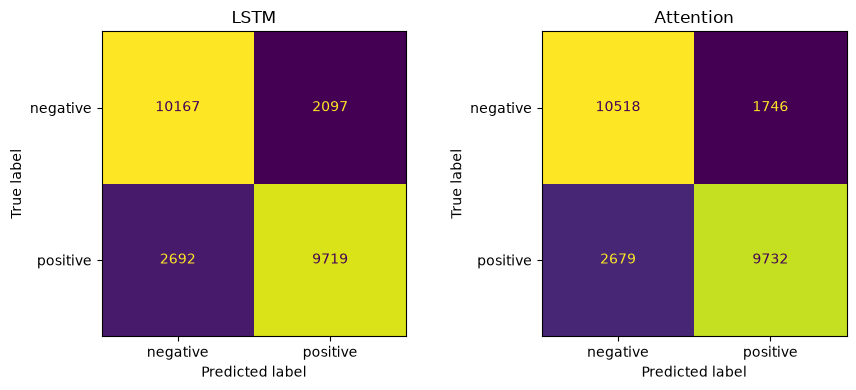

In [13]:
# 24c. Locked checkpoint test evaluation and quantitative table.
result_rows=[];prediction_tables={}
fig,axes=plt.subplots(1,2,figsize=(9,4))
for ax,(architecture,record) in zip(axes,runs.items()):
    model=load_run(record,DEVICE)
    loss,prob,labels=evaluate(model,make_loader(test,vocab,MAX_LENGTH,CONFIG['batch_size']),DEVICE)
    assert np.array_equal(labels,test.label.to_numpy())
    metrics=metric_record(labels,prob)
    result_rows.append(dict(**record,evaluation_split='test',positive_label=1,threshold=.5,
        train_samples=len(train),validation_samples=len(validation),test_samples=len(test),test_loss=loss,**metrics))
    table=test[['sample_id','text','label']].rename(columns={'label':'true_label'}).copy()
    table['positive_probability']=prob;table['predicted_label']=(prob>=.5).astype(int)
    table['correct']=table.true_label.eq(table.predicted_label)
    table['retained_text']=test.tokens.map(lambda t:' '.join(t[:MAX_LENGTH]))
    table['truncated_text']=test.tokens.map(lambda t:' '.join(t[MAX_LENGTH:]))
    table['original_tokens']=test.tokens.map(len)
    table['retained_tokens']=table.original_tokens.clip(upper=MAX_LENGTH)
    table['oov_in_retained']=test.tokens.map(lambda t:sum(w not in vocab for w in t[:MAX_LENGTH]))
    table.to_csv(OUT/f'predictions_{architecture.lower()}.csv',index=False)
    prediction_tables[architecture]=table
    ConfusionMatrixDisplay(confusion_matrix(labels,table.predicted_label,labels=[0,1]),
                           display_labels=['negative','positive']).plot(ax=ax,colorbar=False,values_format='d')
    ax.set_title(architecture)
    del model
results=pd.DataFrame(result_rows);results.to_csv(BASE/'results.csv',index=False)
comparison24=results[['architecture','accuracy','f1','training_time_seconds','parameters']].copy()
comparison24.to_csv(OUT/'section24_model_comparison.csv',index=False)
display(comparison24.rename(columns={'architecture':'Model','accuracy':'Accuracy','f1':'F1',
    'training_time_seconds':'Training time','parameters':'Parameters'}))
display(results[['architecture','precision','recall','f1_macro']])
lstm_row=results.loc[results.architecture.eq('LSTM')].iloc[0]
attention_row=results.loc[results.architecture.eq('Attention')].iloc[0]
print('Chênh lệch số đo Attention - LSTM trong lần chạy này:',
    {'accuracy':float(attention_row.accuracy-lstm_row.accuracy),
     'F1':float(attention_row.f1-lstm_row.f1),
     'training_seconds':float(attention_row.training_time_seconds-lstm_row.training_time_seconds),
     'parameters':int(attention_row.parameters-lstm_row.parameters)})
fig.tight_layout();fig.savefig(BASE/'confusion_matrix.png',dpi=160);plt.show()
attention_model=load_run(runs['Attention'],DEVICE)

,sequence_length,matrix_shape,elements,float32_matrix_MiB,single_query_elements,storage_scope
0,10,10 x 10,100,0.000381,10,one dense float32 score/weight matrix only
1,100,100 x 100,10000,0.038147,100,one dense float32 score/weight matrix only
2,500,500 x 500,250000,0.953674,500,one dense float32 score/weight matrix only
3,1000,1000 x 1000,1000000,3.814697,1000,one dense float32 score/weight matrix only


,sequence_length,mean_forward_ms,repeats,batch_size,d_key,device
0,10,0.092757,30,1,64,cuda
1,100,0.100193,30,1,64,cuda
2,500,0.290410,30,1,64,cuda
3,1000,0.904670,30,1,64,cuda


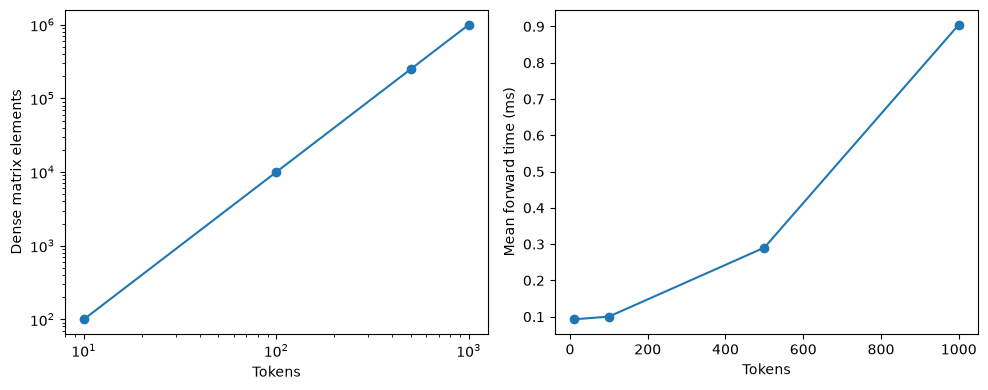

Tỷ lệ tăng tính trực tiếp từ bảng kích thước:


,sequence_length,elements,length_ratio_vs_previous,elements_ratio_vs_previous
0,10,100,NaN,NaN
1,100,10000,10.0,100.0
2,500,250000,5.0,25.0
3,1000,1000000,2.0,4.0


In [14]:
# 25. Computational cost counts, storage estimate and forward-only empirical benchmark.
cost_rows=[]
for length in [10,100,500,1000]:
    cost_rows.append(dict(sequence_length=length,matrix_shape=f'{length} x {length}',
        elements=length**2,float32_matrix_MiB=length**2*4/1024**2,
        single_query_elements=length,storage_scope='one dense float32 score/weight matrix only'))
cost_table=pd.DataFrame(cost_rows);cost_table.to_csv(OUT/'sequence_length_cost.csv',index=False)
display(cost_table)
bench=[]
for length in [10,100,500,1000]:
    torch.manual_seed(25)
    Q=torch.randn(1,length,64,device=DEVICE);K=torch.randn_like(Q);V=torch.randn_like(Q)
    def forward_benchmark():return torch.softmax(torch.bmm(Q,K.transpose(1,2))/8,dim=-1)@V
    with torch.inference_mode():
        for _ in range(5):forward_benchmark()
        if DEVICE.type=='cuda':torch.cuda.synchronize()
        start=time.perf_counter()
        for _ in range(30):forward_benchmark()
        if DEVICE.type=='cuda':torch.cuda.synchronize()
    bench.append(dict(sequence_length=length,mean_forward_ms=(time.perf_counter()-start)/30*1000,
                      repeats=30,batch_size=1,d_key=64,device=str(DEVICE)))
benchmark=pd.DataFrame(bench);benchmark.to_csv(OUT/'sequence_length_benchmark.csv',index=False);display(benchmark)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].loglog(cost_table.sequence_length,cost_table.elements,'o-')
axes[0].set(xlabel='Tokens',ylabel='Dense matrix elements')
axes[1].plot(benchmark.sequence_length,benchmark.mean_forward_ms,'o-')
axes[1].set(xlabel='Tokens',ylabel='Mean forward time (ms)')
fig.tight_layout();fig.savefig(OUT/'sequence_length_cost.png',dpi=160);plt.show()
cost_steps=cost_table[['sequence_length','elements']].copy()
cost_steps['length_ratio_vs_previous']=cost_steps.sequence_length/cost_steps.sequence_length.shift(1)
cost_steps['elements_ratio_vs_previous']=cost_steps.elements/cost_steps.elements.shift(1)
cost_steps.to_csv(OUT/'sequence_length_ratios.csv',index=False)
print('Tỷ lệ tăng tính trực tiếp từ bảng kích thước:');display(cost_steps)


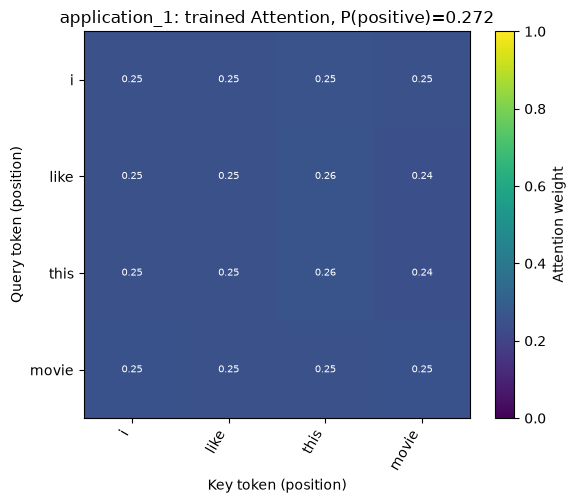

,position,token,token_id,mean_query_attention
0,0,i,10,0.248992
1,1,like,37,0.249220
2,2,this,11,0.255328
3,3,movie,17,0.246461


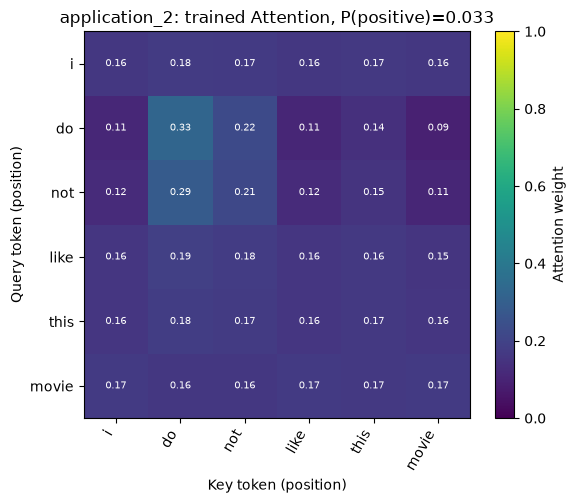

,position,token,token_id,mean_query_attention
0,0,i,10,0.146720
1,1,do,78,0.220096
2,2,not,21,0.187807
3,3,like,37,0.146482
4,4,this,11,0.158927
5,5,movie,17,0.139968


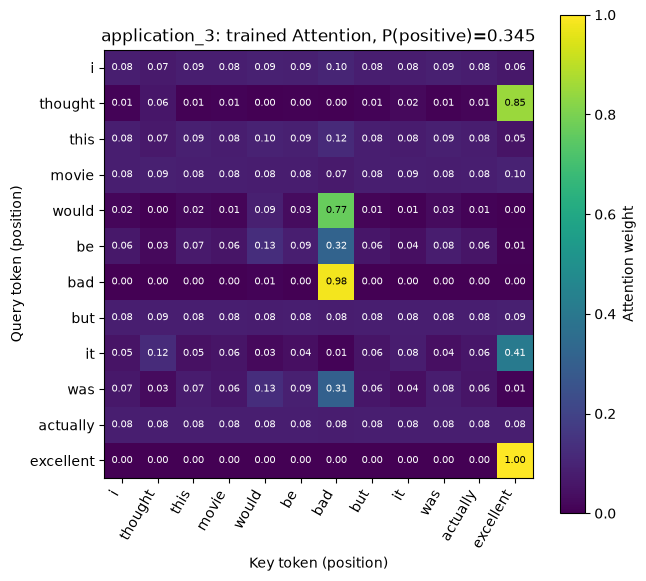

,position,token,token_id,mean_query_attention
0,0,i,10,0.051892
1,1,thought,197,0.053507
2,2,this,11,0.053620
3,3,movie,17,0.051084
4,4,would,59,0.068176
5,5,be,26,0.056015
6,6,bad,77,0.236996
7,7,but,18,0.051482
8,8,it,9,0.050134
9,9,was,13,0.055093


,text,predicted_label,sentiment,positive_probability,predicted_class_probability
0,I like this movie.,0,negative,0.272431,0.727569
1,I do not like this movie.,0,negative,0.033359,0.966641
2,"I thought this movie would be bad, but it was actually excellent.",0,negative,0.344911,0.655089


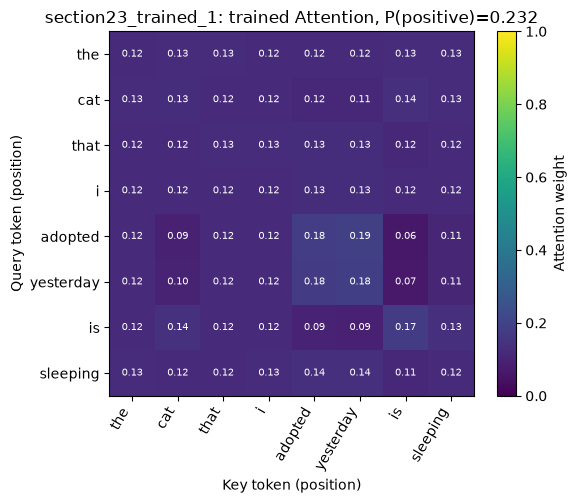

,position,token,token_id,mean_query_attention
0,0,the,2,0.123337
1,1,cat,1103,0.118871
2,2,that,12,0.123590
3,3,i,10,0.123808
4,4,adopted,4871,0.136710
5,5,yesterday,4147,0.137999
6,6,is,7,0.114617
7,7,sleeping,2760,0.121066


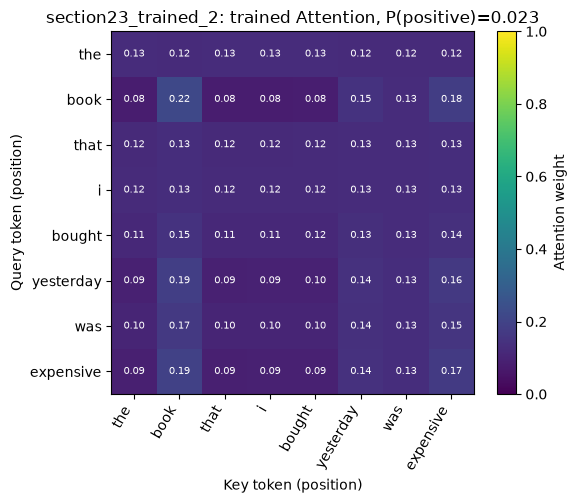

,position,token,token_id,mean_query_attention
0,0,the,2,0.105891
1,1,book,271,0.161706
2,2,that,12,0.105996
3,3,i,10,0.106578
4,4,bought,1277,0.107689
5,5,yesterday,4147,0.135422
6,6,was,13,0.128097
7,7,expensive,3196,0.148621


Top 3 keys theo attention cho các query token được yêu cầu (model đã học):


,sentence,query_token,query_position,key_token,key_position,attention,weights_source
25,The book that I bought yesterday was expensive.,book,1,book,1,0.217641,trained_sentiment_classifier
41,The book that I bought yesterday was expensive.,expensive,7,book,1,0.193838,trained_sentiment_classifier
13,The cat that I adopted yesterday is sleeping.,adopted,4,yesterday,5,0.187787,trained_sentiment_classifier
12,The cat that I adopted yesterday is sleeping.,adopted,4,adopted,4,0.183470,trained_sentiment_classifier
31,The book that I bought yesterday was expensive.,book,1,expensive,7,0.181278,trained_sentiment_classifier
47,The book that I bought yesterday was expensive.,expensive,7,expensive,7,0.169903,trained_sentiment_classifier
29,The book that I bought yesterday was expensive.,book,1,yesterday,5,0.147417,trained_sentiment_classifier
33,The book that I bought yesterday was expensive.,bought,4,book,1,0.145018,trained_sentiment_classifier
45,The book that I bought yesterday was expensive.,expensive,7,yesterday,5,0.143865,trained_sentiment_classifier
6,The cat that I adopted yesterday is sleeping.,cat,1,is,6,0.138989,trained_sentiment_classifier


In [15]:
# 26. End-to-end raw-text application with learned attention visualization.
def inspect_text(text,tag,show=True):
    tokens=tokenize(text);kept=tokens[:MAX_LENGTH] or ['<UNK>']
    ids,lengths,_=collate_reviews([(encode(tokens,vocab,MAX_LENGTH),0.)])
    with torch.inference_mode():
        logits,weights,context=attention_model(ids.to(DEVICE),lengths,return_attention=True)
    prob=float(torch.sigmoid(logits)[0].cpu());A=weights[0,:len(kept),:len(kept)].cpu().numpy()
    # Mean over valid query rows is the model's mean-pooling effective value weight.
    effective=A.mean(axis=0)
    token_table=pd.DataFrame({'position':range(len(kept)),'token':kept,
        'token_id':encode(tokens,vocab,MAX_LENGTH),'mean_query_attention':effective})
    token_table.to_csv(OUT/f'{tag}_tokens.csv',index=False)
    np.save(OUT/f'{tag}_attention.npy',A)
    labels=[f'{i}:{t}' for i,t in enumerate(kept)]
    pd.DataFrame(A,index=labels,columns=labels).to_csv(OUT/f'{tag}_matrix.csv')
    if show:
        path=BASE/'attention_heatmap.png' if tag=='application_1' else OUT/f'{tag}_heatmap.png'
        heatmap(A,kept,f'{tag}: trained Attention, P(positive)={prob:.3f}',path)
        display(token_table)
    return dict(text=text,predicted_label=int(prob>=.5),sentiment='positive' if prob>=.5 else 'negative',positive_probability=prob,
        predicted_class_probability=max(prob,1-prob),original_tokens=len(tokens),retained_tokens=len(kept),
        retained_text=' '.join(kept),truncated_text=' '.join(tokens[MAX_LENGTH:]),
        matrix_file=f'outputs/{tag}_attention.npy',token_file=f'outputs/{tag}_tokens.csv')

application_texts=['I like this movie.','I do not like this movie.',
                  'I thought this movie would be bad, but it was actually excellent.']
application_rows=[inspect_text(text,f'application_{i+1}') for i,text in enumerate(application_texts)]
application_table=pd.DataFrame(application_rows)
application_table.to_csv(OUT/'application_predictions.csv',index=False)
with pd.option_context('display.max_colwidth',None):
    display(application_table[['text','predicted_label','sentiment','positive_probability','predicted_class_probability']])
trained_probe_rows=[]
# Additional trained sentence heatmaps complement the untrained section 23 demonstrations.
for i,text in enumerate(sentences23):
    tag=f'section23_trained_{i+1}'
    inspect_text(text,tag)
    trained_A=np.load(OUT/f'{tag}_attention.npy')
    trained_tokens=tokenize(text)[:MAX_LENGTH]
    probes=['cat','adopted','sleeping'] if i==0 else ['book','bought','expensive']
    for query_token in probes:
        qi=trained_tokens.index(query_token)
        for ki,key_token in enumerate(trained_tokens):
            trained_probe_rows.append(dict(sentence=text,query_token=query_token,query_position=qi,
                key_token=key_token,key_position=ki,attention=float(trained_A[qi,ki]),weights_source='trained_sentiment_classifier'))
trained_probe_table=pd.DataFrame(trained_probe_rows)
trained_probe_table.to_csv(OUT/'section23_trained_token_rows.csv',index=False)
trained_top=(trained_probe_table.sort_values('attention',ascending=False)
    .groupby(['sentence','query_token'],sort=False).head(3))
trained_top.to_csv(OUT/'section23_trained_top_keys.csv',index=False)
print('Top 3 keys theo attention cho các query token được yêu cầu (model đã học):');display(trained_top)

,sample_id,text,true_label,predicted_label,positive_probability,correct,original_tokens,retained_tokens,oov_in_retained,retained_text,truncated_text
0,test:0,"I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, CG that doesn't match the background, and painfully one-dimensional characters cannot be overcome with a 'sci-fi' setting. (I'm sure there are those of you out there who think Babylon 5 is good sci-fi TV. It's not. It's clichéd and uninspiring.) While US viewers might like emotion and character development, sci-fi is a genre that does not take itself seriously (cf. Star Trek). It may treat important issues, yet not as a serious philosophy. It's really difficult to care about the characters here as they are not simply foolish, just missing a spark of life. Their actions and reactions are wooden and predictable, often painful to watch. The makers of Earth KNOW it's rubbish as they have to always say ""Gene Roddenberry's Earth..."" otherwise people would not continue watching. Roddenberry's ashes must be turning in their orbit as this dull, cheap, poorly edited (watching it without advert breaks really brings this home) trudging Trabant of a show lumbers into space. Spoiler. So, kill off a main character. And then bring him back as another actor. Jeeez! Dallas all over again.",0,0,0.217997,True,240,100,1,i love sci fi and am willing to put up with a lot sci fi movies tv are usually underfunded under appreciated and misunderstood i tried to like this i really did but it is to good tv sci fi as babylon 5 is to star trek the original silly prosthetics cheap cardboard sets stilted dialogues cg that doesn't match the background and painfully one dimensional characters cannot be overcome with a sci fi setting i'm sure there are those of you out there who think babylon 5 is good sci fi tv it's not it's clich d and uninspiring,while us viewers might like emotion and character development sci fi is a genre that does not take itself seriously cf star trek it may treat important issues yet not as a serious philosophy it's really difficult to care about the characters here as they are not simply foolish just missing a spark of life their actions and reactions are wooden and predictable often painful to watch the makers of earth know it's rubbish as they have to always say gene roddenberry's earth otherwise people would not continue watching roddenberry's ashes must be turning in their orbit as this dull cheap poorly edited watching it without advert breaks really brings this home trudging trabant of a show lumbers into space spoiler so kill off a main character and then bring him back as another actor jeeez dallas all over again
1,test:1,"Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car chases, fights with the great Van Damme kick style, shooting battles with the 40 shell load shotgun, and even terrorist style bombs. All of this is entertaining and competently handled but there is nothing that really blows you away if you've seen your share before.<br /><br />The plot is made interesting by the inclusion of a rabbit, which is clever but hardly profound. Many of the characters are heavily stereotyped -- the angry veterans, the terrified illegal aliens, the crooked cops, the indifferent feds, the bitchy tough lady station head, the crooked politician, the fat federale who looks like he was typecast as the Mexican in a Hollywood movie from the 1940s. All passably acted but again nothing special.<br /><br />I thought the main villains were pretty well done and fairly well acted. By the end of the movie you certainly knew who the good guys were and weren't. There was an emotional lift as the really bad ones got their just deserts. Ver

Full text, all attention rows, and span perturbation measurements saved; learner chooses examples and hypotheses.


,sample_id,true_label,predicted_label,positive_probability,correct,retained_text
0,test:0,0,0,0.217997,True,i love sci fi and am willing to put up with a lot sci fi movies tv are usually underfunded under appreciated and mis...
3,test:4,0,1,0.758342,False,first off let me say if you haven't enjoyed a van damme movie since bloodsport you probably will not like this movie...


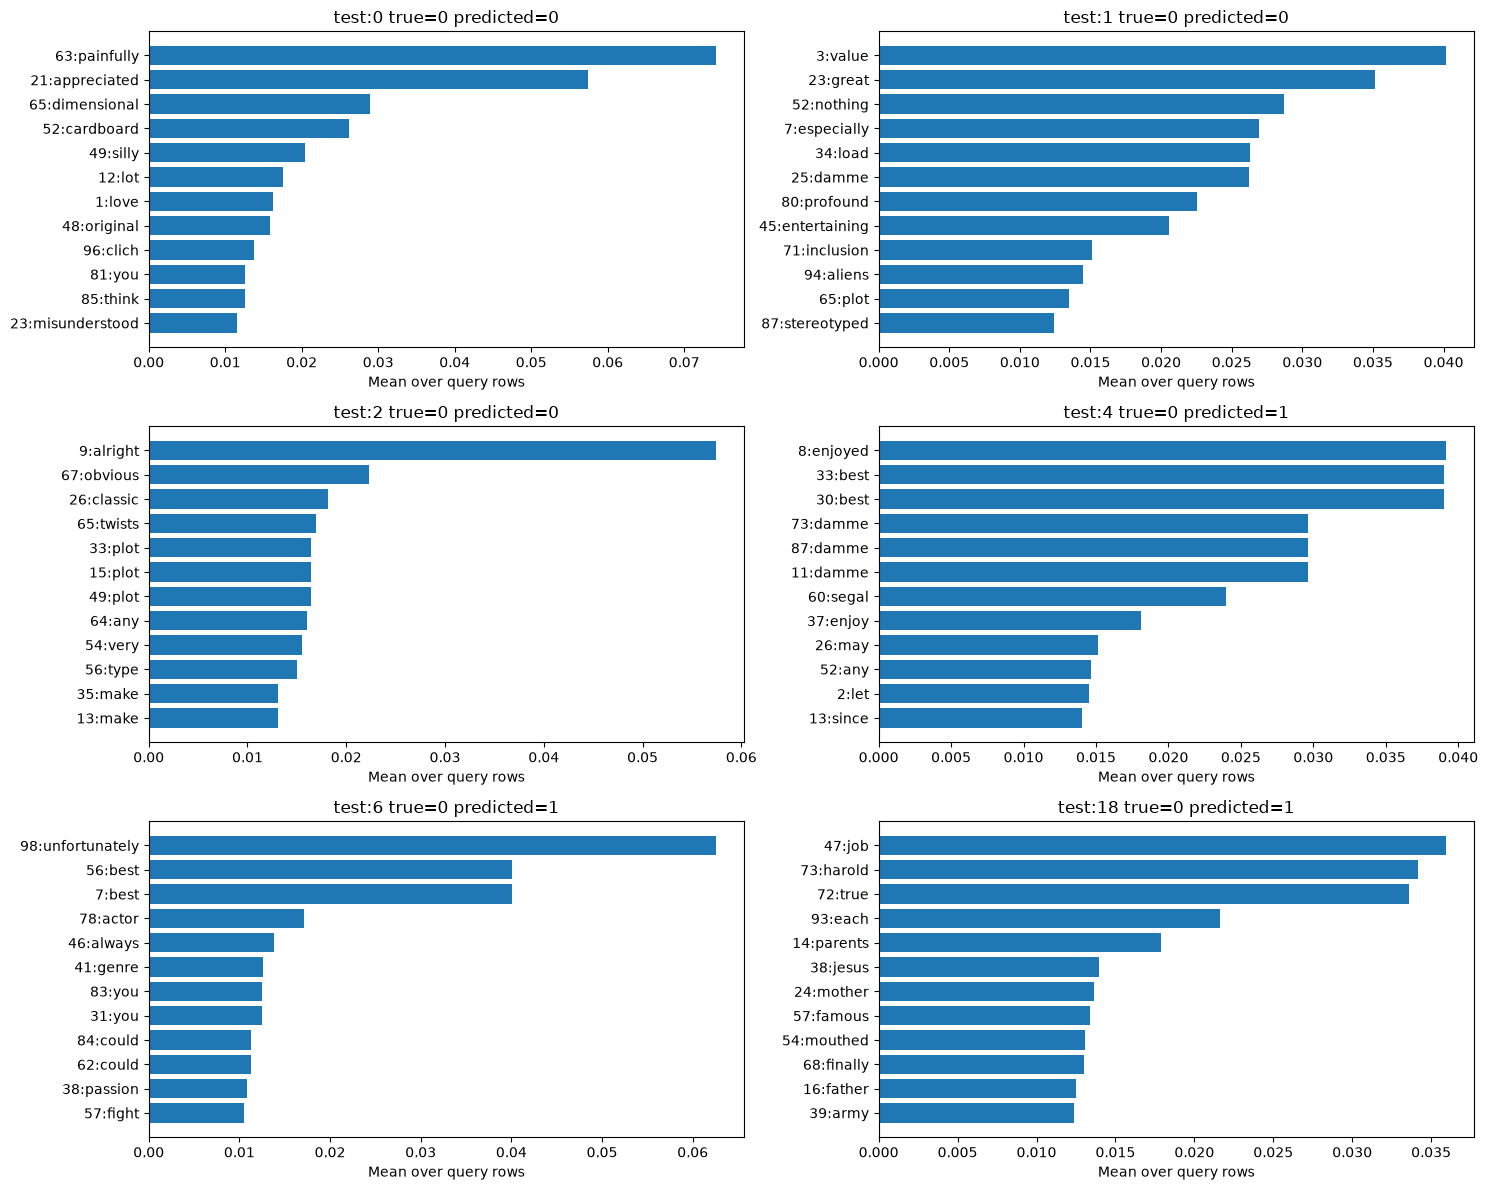

Số mẫu correct: 3 ; incorrect: 3
Bảng có cột trống để người học tự phân loại lỗi và viết hypothesis: outputs/error_analysis_template.csv


,sample_id,true_label,predicted_label,correct,matrix_file,token_file
0,test:0,0,0,True,outputs/error_candidate_1_attention.npy,outputs/error_candidate_1_tokens.csv
1,test:1,0,0,True,outputs/error_candidate_2_attention.npy,outputs/error_candidate_2_tokens.csv
2,test:2,0,0,True,outputs/error_candidate_3_attention.npy,outputs/error_candidate_3_tokens.csv
3,test:4,0,1,False,outputs/error_candidate_4_attention.npy,outputs/error_candidate_4_tokens.csv
4,test:6,0,1,False,outputs/error_candidate_5_attention.npy,outputs/error_candidate_5_tokens.csv
5,test:18,0,1,False,outputs/error_candidate_6_attention.npy,outputs/error_candidate_6_tokens.csv


Đo thay đổi probability khi thay từng span bằng UNK (không tự gán nguyên nhân lỗi):


,sample_id,start,end_exclusive,original_probability,perturbed_probability,probability_delta,removed_span
0,test:0,0,10,0.217997,0.071931,-0.146066,i love sci fi and am willing to put up
1,test:0,10,20,0.217997,0.085316,-0.132681,with a lot sci fi movies tv are usually underfunded
2,test:0,20,30,0.217997,0.047332,-0.170665,under appreciated and misunderstood i tried to like this i
3,test:0,30,40,0.217997,0.079744,-0.138253,really did but it is to good tv sci fi
4,test:0,40,50,0.217997,0.183264,-0.034733,as babylon 5 is to star trek the original silly
5,test:0,50,60,0.217997,0.276616,0.058619,prosthetics cheap cardboard sets stilted dialogues cg that doesn't match
6,test:0,60,70,0.217997,0.436362,0.218365,the background and painfully one dimensional characters cannot be overcome
7,test:0,70,80,0.217997,0.085313,-0.132684,with a sci fi setting i'm sure there are those
8,test:0,80,90,0.217997,0.079752,-0.138245,of you out there who think babylon 5 is good
9,test:0,90,100,0.217997,0.115160,-0.102837,sci fi tv it's not it's clich d and uninspiring


In [16]:
# 26 / 27. Unannotated application/error-analysis candidates: no AI-generated causes.
pool=prediction_tables['Attention']
pool.to_csv(OUT/'error_analysis_candidates.csv',index=False)
selected=pd.concat([pool.loc[pool.correct].head(3),pool.loc[~pool.correct].head(3)],ignore_index=True)
assert len(selected)==6 and selected.correct.sum()==3
selected.to_csv(OUT/'six_examples_unannotated.csv',index=False)
analysis_template=selected.copy()
for field in ['error_category','expected_important_tokens','attention_observation','hypothesis','behavior_evidence','limitations']:
    analysis_template[field]=''
analysis_template.to_csv(OUT/'error_analysis_template.csv',index=False)
artifact_rows=[];perturb_rows=[]
for i,row in selected.iterrows():
    tag=f'error_candidate_{i+1}'
    artifact=inspect_text(row.text,tag,show=False)
    artifact_rows.append(dict(sample_id=row.sample_id,true_label=int(row.true_label),correct=bool(row.correct),**artifact))
    # Mechanically replace each consecutive 10-token span with UNK; preserve all positions.
    tokens=tokenize(row.text)[:MAX_LENGTH]
    original_ids=encode(tokens,vocab,MAX_LENGTH)
    variants=[original_ids]
    spans=[]
    for left in range(0,len(original_ids),10):
        right=min(left+10,len(original_ids));variant=original_ids.copy()
        variant[left:right]=[1]*(right-left);variants.append(variant);spans.append((left,right))
    ids,lengths,_=collate_reviews([(v,0.) for v in variants])
    with torch.inference_mode():probs=torch.sigmoid(attention_model(ids.to(DEVICE),lengths)).cpu().numpy()
    for (left,right),p in zip(spans,probs[1:]):
        perturb_rows.append(dict(sample_id=row.sample_id,start=left,end_exclusive=right,
            original_probability=float(probs[0]),perturbed_probability=float(p),
            probability_delta=float(p-probs[0]),removed_span=' '.join(tokens[left:right])))
artifacts=pd.DataFrame(artifact_rows);artifacts.to_csv(OUT/'error_attention_artifacts.csv',index=False)
pd.DataFrame(perturb_rows).to_csv(OUT/'span_perturbations.csv',index=False)
with pd.option_context('display.max_colwidth',None):
    display(selected[['sample_id','text','true_label','predicted_label','positive_probability','correct',
        'original_tokens','retained_tokens','oov_in_retained','retained_text','truncated_text']])
print('Full text, all attention rows, and span perturbation measurements saved; learner chooses examples and hypotheses.')
# Application: additional labeled test reviews provide a correct/incorrect pool if all three supplied sentences agree.
application_cases=artifacts.groupby('correct',group_keys=False).head(1)
application_cases.to_csv(OUT/'application_labeled_candidates.csv',index=False)
display(application_cases[['sample_id','true_label','predicted_label','positive_probability','correct','retained_text']])
# Readable attention bars for six candidates (full attention matrices remain in CSV/NPY).
fig,axes=plt.subplots(3,2,figsize=(15,12))
for ax,(i,row) in zip(axes.flat,selected.iterrows()):
    tokens=pd.read_csv(OUT/f'error_candidate_{i+1}_tokens.csv')
    top=tokens.nlargest(12,'mean_query_attention').sort_values('mean_query_attention')
    ax.barh([f'{r.position}:{r.token}' for r in top.itertuples()],top.mean_query_attention)
    ax.set(title=f'{row.sample_id} true={row.true_label} predicted={row.predicted_label}',xlabel='Mean over query rows')
fig.tight_layout();fig.savefig(OUT/'error_candidates_attention.png',dpi=160);plt.show()
print('Số mẫu correct:',int(selected.correct.sum()),'; incorrect:',int((~selected.correct).sum()))
print('Bảng có cột trống để người học tự phân loại lỗi và viết hypothesis: outputs/error_analysis_template.csv')
display(artifacts[['sample_id','true_label','predicted_label','correct','matrix_file','token_file']])
print('Đo thay đổi probability khi thay từng span bằng UNK (không tự gán nguyên nhân lỗi):')
display(pd.DataFrame(perturb_rows))


In [17]:
# 28. Measured model behavior for comparison; written theory answers remain with the learner.
ids,lengths,_=collate_reviews([(encode(tokenize(application_texts[2]),vocab,MAX_LENGTH),0.)])
with torch.inference_mode():
    original=attention_model(ids.to(DEVICE),lengths)
    padded=torch.nn.functional.pad(ids,(0,7))
    pad_prob=attention_model(padded.to(DEVICE),lengths)
    permutation=torch.arange(ids.shape[1]-1,-1,-1)
    reordered=attention_model(ids[:,permutation].to(DEVICE),lengths)
assert torch.allclose(original,pad_prob,atol=1e-6)
behavior=pd.DataFrame([dict(probe='right padding: same valid tokens',logit_original=float(original[0]),logit_modified=float(pad_prob[0])),
    dict(probe='reverse same token IDs',logit_original=float(original[0]),logit_modified=float(reordered[0]))])
behavior.to_csv(OUT/'model_behavior_checks.csv',index=False);display(behavior)


,probe,logit_original,logit_modified
0,right padding: same valid tokens,-0.641486,-0.641486
1,reverse same token IDs,-0.641486,-0.641486


In [18]:
# 29. Attention cost at T=1000 and T=10000: counts and storage, no large allocation.
cost29=pd.DataFrame([dict(sequence_length=T,matrix_shape=f'{T} x {T}',
    elements=T*T,float32_matrix_MiB=T*T*4/1024**2) for T in [1000,10000]])
cost29.to_csv(OUT/'section29_attention_cost.csv',index=False)
display(cost29)
print('Tỷ lệ chiều dài:',int(cost29.iloc[1].sequence_length/cost29.iloc[0].sequence_length),
      '; tỷ lệ số phần tử:',int(cost29.iloc[1].elements/cost29.iloc[0].elements))
print('Đây là số byte của một matrix float32; không cấp phát matrix T=10000 trong thí nghiệm này.')


,sequence_length,matrix_shape,elements,float32_matrix_MiB
0,1000,1000 x 1000,1000000,3.814697
1,10000,10000 x 10000,100000000,381.469727


Tỷ lệ chiều dài: 10 ; tỷ lệ số phần tử: 100
Đây là số byte của một matrix float32; không cấp phát matrix T=10000 trong thí nghiệm này.


In [19]:
# 32. Implementation verification, execution metadata and deliverable status.
# PyTorch vs NumPy agreement on learned Q/K/V for one unpadded sequence.
with torch.inference_mode():
    e=attention_model.embedding(ids.to(DEVICE))
    q=attention_model.WQ(e)[0].cpu().numpy();k=attention_model.WK(e)[0].cpu().numpy();v=attention_model.WV(e)[0].cpu().numpy()
    _,torch_a,torch_c=attention_model(ids.to(DEVICE),lengths,return_attention=True)
_,numpy_a,numpy_c=scaled_dot_product_attention(q,k,v)
assert np.allclose(numpy_a,torch_a[0].cpu().numpy(),atol=2e-6)
assert np.allclose(numpy_c,torch_c[0].cpu().numpy(),atol=2e-5)
verification=dict(padding_invariance=True,numpy_torch_attention_agreement=True,
    numpy_torch_context_agreement=True,split_overlap=0,test_used_for_selection=False,
    section21='Missing numerical input matrices; student must obtain them',
    handwritten_scans_complete=False)
(OUT/'verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
metadata=dict(config=CONFIG,max_length=MAX_LENGTH,device=str(DEVICE),
    packages={p:importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','torch','scikit-learn','nbformat','nbclient']},
    data_sha256={p.name:sha256(p) for p in (BASE/'data').iterdir() if p.is_file()},
    architecture='single-head full self-attention, no positional encoding, masked mean pooling',
    prediction_confirmation=confirmation)
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
required=['README.md','calculations.md','prediction.md','attention_numpy.py','self_attention.ipynb',
          'results.csv','attention_heatmap.png','confusion_matrix.png','error_analysis.md','reflection.md']
display(pd.DataFrame([dict(deliverable=f,exists=(BASE/f).exists()) for f in required]))
display(pd.DataFrame([dict(scan=f,exists=(BASE/'scans'/f).exists()) for f in
    ['calculations_scan.pdf','prediction_scan.pdf','error_analysis_scan.pdf','reflection_scan.pdf']]))
print('Technical outputs generated; handwritten calculations/answers and learner verification remain separate.')

,deliverable,exists
0,README.md,True
1,calculations.md,False
2,prediction.md,False
3,attention_numpy.py,True
4,self_attention.ipynb,True
5,results.csv,True
6,attention_heatmap.png,True
7,confusion_matrix.png,True
8,error_analysis.md,False
9,reflection.md,False


,scan,exists
0,calculations_scan.pdf,False
1,prediction_scan.pdf,False
2,error_analysis_scan.pdf,False
3,reflection_scan.pdf,False


Technical outputs generated; handwritten calculations/answers and learner verification remain separate.
